# Data Cleaning and Preprocessing

This notebook prepares the dataset for modelling. Each step is paired with a short diagnostic so the impact is visible:

- remove duplicates
- handle missing values
- drop columns that leak the target or carry no signal
- inspect outliers and value ranges
- validate dtypes and final shape
- persist the cleaned frame for downstream notebooks

In [29]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)
pd.set_option("display.max_columns", 60)

df = pd.read_csv("../data/raw/DataCoSupplyChainDataset.csv", encoding="latin1")
print("Initial shape:", df.shape)

Initial shape: (180519, 53)


## 1. Duplicate Rows

In [30]:
def check_duplicates(df):
    duplicates = df.duplicated().sum()
    print(f"Number of duplicate samples: {duplicates}")
    return duplicates

_ = check_duplicates(df)
before = df.shape[0]
df = df.drop_duplicates()
print(f"Rows: {before} -> {df.shape[0]} (removed {before - df.shape[0]})")

Number of duplicate samples: 0
Rows: 180519 -> 180519 (removed 0)


## 2. Missing Values

Visualise per-column missingness, then drop columns dominated by NaNs (>80% missing) since imputation cannot recover real signal there.

In [31]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_summary = pd.DataFrame({"missing": missing, "pct": missing_pct})
missing_summary = missing_summary[missing_summary["missing"] > 0].sort_values("missing", ascending=False)
missing_summary

,missing,pct
Product Description,180519,100.00
Order Zipcode,155679,86.24
Customer Lname,8,0.00
Customer Zipcode,3,0.00


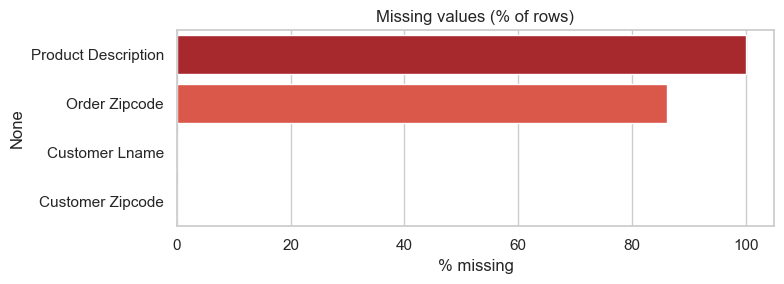

In [32]:
if not missing_summary.empty:
    fig, ax = plt.subplots(figsize=(8, 3))
    sns.barplot(
        x=missing_summary["pct"],
        y=missing_summary.index,
        hue=missing_summary.index,   
        legend=False,              
        palette="Reds_r",
        ax=ax
    )
    ax.set_title("Missing values (% of rows)")
    ax.set_xlabel("% missing")
    plt.tight_layout()
    plt.show()

In [33]:
# Drop columns that are too sparse to recover (>=80% missing) or carry no signal.
# Customer Lname / Customer Zipcode have only a handful of NaNs, but they are PII and not
# useful for modelling shipping outcomes — drop them outright.
cols_to_drop = [
    "Customer Lname",
    "Customer Zipcode",
    "Order Zipcode",
    "Product Description",
]
df = df.drop(columns=[c for c in cols_to_drop if c in df.columns])
print("Dropped:", cols_to_drop)

Dropped: ['Customer Lname', 'Customer Zipcode', 'Order Zipcode', 'Product Description']


## 3. Drop Target-Leaking and Useless Columns

- `Delivery Status` is essentially the target in disguise (e.g., "Late delivery" → `Late_delivery_risk == 1`). Keeping it would leak the target.
- `Product Status` is constant.
- PII / identifier-like columns add nothing to a tree model and bloat encoding (`Customer Email`, `Customer Fname`, `Customer Password`, `Customer Street`, `Product Image`).

In [34]:
# Constant column check
nunique = df.nunique()
constant_cols = nunique[nunique <= 1].index.tolist()
print("Constant columns:", constant_cols)

leak_or_noise = [
    "Delivery Status",       # leakage
    "Product Status",        # constant
    "Customer Email",        # PII / identifier
    "Customer Fname",
    "Customer Password",
    "Customer Street",
    "Product Image",
]
df = df.drop(columns=[c for c in leak_or_noise if c in df.columns], errors="ignore")
print("Dropped leak/noise columns. New shape:", df.shape)

Constant columns: ['Customer Email', 'Customer Password', 'Product Status']
Dropped leak/noise columns. New shape: (180519, 42)


In [35]:
# Confirm there are no more missing values
remaining = df.isnull().sum()
print("Remaining columns with NaNs:")
print(remaining[remaining > 0] if remaining.sum() else "None")

Remaining columns with NaNs:
None


## 4. Dtype Validation

Convert order/shipping date columns to `datetime` and verify numeric columns are numeric.

In [36]:
for col in ["order date (DateOrders)", "shipping date (DateOrders)"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

df.dtypes.value_counts()

object            15
int64             13
float64           12
datetime64[ns]     2
Name: count, dtype: int64

## 5. Outlier Inspection

We **do not** clip outliers — tree-based models handle them natively. But it is worth surfacing the extremes so we know what we are feeding the model.

In [37]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Days for shipping (real),180519.0,3.497654,0.0,2.0,3.0,5.0,6.0,1.623722
Days for shipment (scheduled),180519.0,2.931847,0.0,2.0,4.0,4.0,4.0,1.374449
Benefit per order,180519.0,21.974989,-4274.97998,7.0,31.52,64.800003,911.799988,104.433526
Sales per customer,180519.0,183.107609,7.49,104.379997,163.990005,247.399994,1939.98999,120.04367
Late_delivery_risk,180519.0,0.548291,0.0,0.0,1.0,1.0,1.0,0.497664
Category Id,180519.0,31.851451,2.0,18.0,29.0,45.0,76.0,15.640064
Customer Id,180519.0,6691.379495,1.0,3258.5,6457.0,9779.0,20757.0,4162.918106
Department Id,180519.0,5.44346,2.0,4.0,5.0,7.0,12.0,1.629246
Latitude,180519.0,29.719955,-33.937553,18.265432,33.144863,39.279617,48.781933,9.813646
Longitude,180519.0,-84.915675,-158.025986,-98.446312,-76.847908,-66.370583,115.263077,21.433241


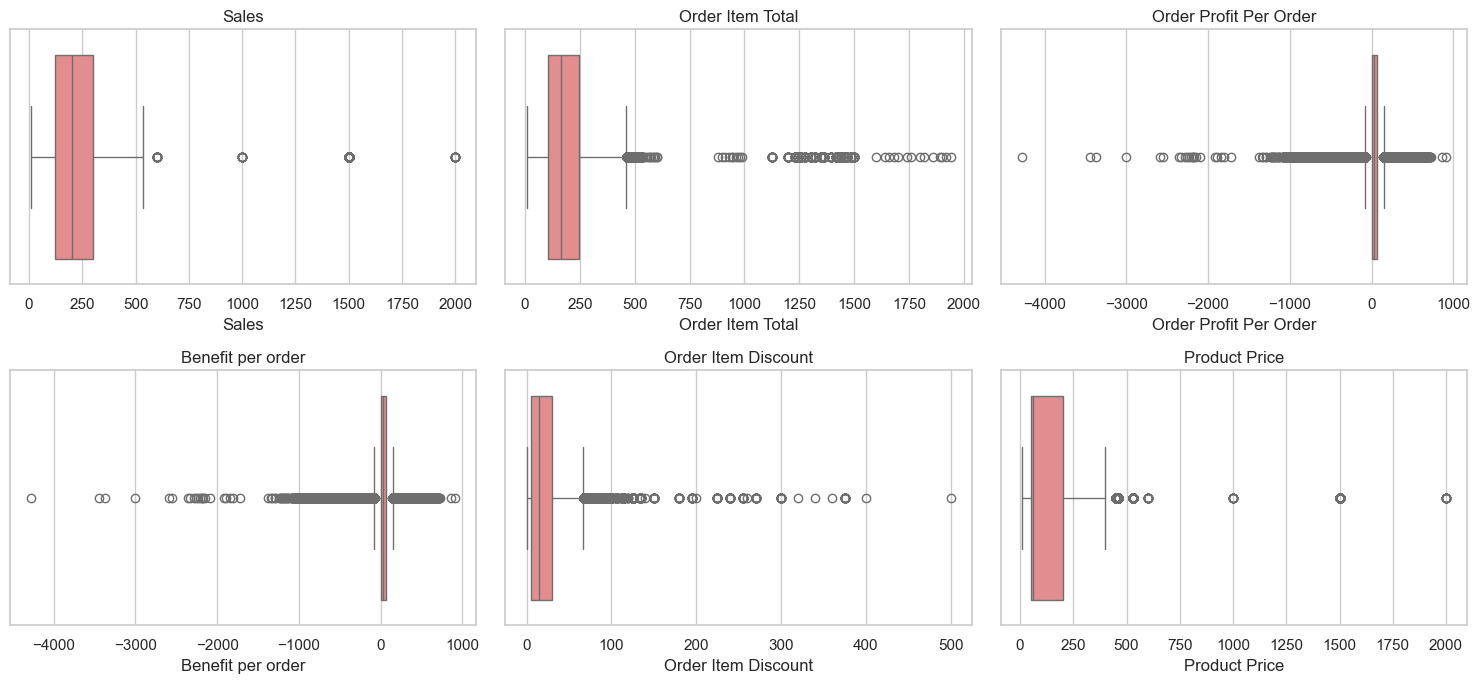

In [38]:
candidates = [
    "Sales", "Order Item Total", "Order Profit Per Order",
    "Benefit per order", "Order Item Discount", "Product Price",
]
candidates = [c for c in candidates if c in df.columns]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.flatten(), candidates):
    sns.boxplot(x=df[col], ax=ax, color="lightcoral")
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [39]:
# IQR-based outlier counts (informational only)
def iqr_outliers(s: pd.Series) -> int:
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

outlier_counts = pd.Series({c: iqr_outliers(df[c]) for c in candidates})
outlier_counts.sort_values(ascending=False)

Order Profit Per Order    18942
Benefit per order         18942
Order Item Discount        7537
Product Price              2048
Order Item Total           1943
Sales                       488
dtype: int64

## 6. Sanity Checks Against Targets

Targets should remain untouched after cleaning.

In [40]:
TARGET_SHIPPING = "Days for shipping (real)"
TARGET_LATE = "Late_delivery_risk"

print(df[TARGET_SHIPPING].describe())
print()
print(df[TARGET_LATE].value_counts(normalize=True).round(3))

count    180519.000000
mean          3.497654
std           1.623722
min           0.000000
25%           2.000000
50%           3.000000
75%           5.000000
max           6.000000
Name: Days for shipping (real), dtype: float64

Late_delivery_risk
1    0.548
0    0.452
Name: proportion, dtype: float64


## 7. Final Shape and Persist

In [41]:
print("Final dataset shape:", df.shape)
df.head()

Final dataset shape: (180519, 42)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Id,Customer Segment,Customer State,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Card Id,Product Category Id,Product Name,Product Price,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,0,73,Sporting Goods,Caguas,Puerto Rico,20755,Consumer,PR,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,2018-01-31 22:56:00,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,1360,73,Smart watch,327.75,2018-02-03 22:56:00,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,1,73,Sporting Goods,Caguas,Puerto Rico,19492,Consumer,PR,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,2018-01-13 12:27:00,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,1360,73,Smart watch,327.75,2018-01-18 12:27:00,Standard Class
2,CASH,4,4,-247.779999,309.720001,0,73,Sporting Goods,San Jose,EE. UU.,19491,Consumer,CA,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,2018-01-13 12:06:00,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,1360,73,Smart watch,327.75,2018-01-17 12:06:00,Standard Class
3,DEBIT,3,4,22.860001,304.809998,0,73,Sporting Goods,Los Angeles,EE. UU.,19490,Home Office,CA,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,2018-01-13 11:45:00,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,1360,73,Smart watch,327.75,2018-01-16 11:45:00,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,0,73,Sporting Goods,Caguas,Puerto Rico,19489,Corporate,PR,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,2018-01-13 11:24:00,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,1360,73,Smart watch,327.75,2018-01-15 11:24:00,Standard Class


In [42]:
os.makedirs("../data/preprocessed", exist_ok=True)
out_path = "../data/preprocessed/cleaned.csv"
df.to_csv(out_path, index=False)
print("Saved to", out_path)

Saved to ../data/preprocessed/cleaned.csv
